# Wine Quality Prediction — End-to-End Supervised Machine Learning

**Portfolio project | Classification + Regression | Scikit-learn Pipelines**

## Business problem
A wine producer wants to understand the physicochemical properties associated with wine quality and build two predictive models:

1. **Classification:** predict whether a wine is in the higher-quality group (`quality >= 6`).
2. **Regression:** predict the wine's numeric quality score.

This is an educational benchmark, not a production wine-certification system. We will compare multiple model families, use cross-validation for model selection, evaluate the selected model on an untouched test set, and save the complete preprocessing + model pipeline.

### What you will demonstrate in interviews
- EDA and data quality checks
- Feature/target separation and leakage prevention
- `ColumnTransformer` + `Pipeline`
- Classification and regression algorithm families
- Cross-validation and model selection
- Metrics, error analysis, and model persistence

**Dataset:** UCI Wine Quality (red and white wine variants). [Official dataset page](https://archive.ics.uci.edu/dataset/186/wine+quality)

## 0. Install dependencies

Run this cell once in your notebook environment. If the installation finishes, restart the kernel only if Jupyter asks you to.

In [5]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn joblib


[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 1. Imports and reproducibility

In [6]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold, KFold
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC, SVR
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, ConfusionMatrixDisplay,
    mean_absolute_error, mean_squared_error, r2_score
)
import joblib

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid')

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / 'data' / 'raw'
MODEL_DIR = PROJECT_DIR / 'models'
REPORT_DIR = PROJECT_DIR / 'reports'
for folder in (DATA_DIR, MODEL_DIR, REPORT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print('Working directory:', PROJECT_DIR.resolve())

Working directory: /Users/k.r.saravanadeep/PycharmProjects/wine-quality-ml-notebook


## 2. Load the dataset

The official UCI files are semicolon-separated CSVs. We combine red and white wines and add `wine_type` as an input feature. The notebook tries the official download URLs first.

If the download fails, download `winequality-red.csv` and `winequality-white.csv` from the [UCI dataset page](https://archive.ics.uci.edu/dataset/186/wine+quality), save them in `data/raw/`, and rerun this cell.

In [7]:
red_path = DATA_DIR / 'winequality-red.csv'
white_path = DATA_DIR / 'winequality-white.csv'
red_url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv'
white_url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv'

def read_wine_file(local_path, url, wine_type):
    if local_path.exists():
        frame = pd.read_csv(local_path, sep=';')
    else:
        try:
            frame = pd.read_csv(url, sep=';')
            frame.to_csv(local_path, index=False, sep=';')
        except Exception as exc:
            raise RuntimeError(
                f'Could not download {wine_type} wine data. Download the two CSV files from '
                'https://archive.ics.uci.edu/dataset/186/wine+quality and place them in data/raw/. '
                f'Original error: {exc}'
            ) from exc
    frame['wine_type'] = wine_type
    return frame

red = read_wine_file(red_path, red_url, 'red')
white = read_wine_file(white_path, white_url, 'white')
df = pd.concat([red, white], ignore_index=True)

# Standardize column labels to avoid accidental whitespace issues.
df.columns = [col.strip().lower().replace(' ', '_') for col in df.columns]

print(f'Shape: {df.shape[0]:,} rows × {df.shape[1]} columns')
display(df.head())
print('\nWine type counts:')
display(df['wine_type'].value_counts().rename_axis('wine_type').to_frame('rows'))

Shape: 6,497 rows × 13 columns


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red



Wine type counts:


,rows
wine_type,
white,4898
red,1599


## 3. Understand the data

In [8]:
print('Data types and non-null counts:')
df.info()

print('\nMissing values by column:')
display(df.isna().sum().sort_values(ascending=False).to_frame('missing_count'))

print('\nDuplicate rows:', df.duplicated().sum())
print('\nQuality distribution:')
display(df['quality'].value_counts().sort_index().rename_axis('quality').to_frame('count'))

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         6497 non-null   float64
 1   volatile_acidity      6497 non-null   float64
 2   citric_acid           6497 non-null   float64
 3   residual_sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free_sulfur_dioxide   6497 non-null   float64
 6   total_sulfur_dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   ph                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  wine_type             6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 660.0 KB

Missing values by column:


,missing_count
fixed_acidity,0
volatile_acidity,0
citric_acid,0
residual_sugar,0
chlorides,0
free_sulfur_dioxide,0
total_sulfur_dioxide,0
density,0
ph,0
sulphates,0



Duplicate rows: 1177

Quality distribution:


,count
quality,
3,30
4,216
5,2138
6,2836
7,1079
8,193
9,5


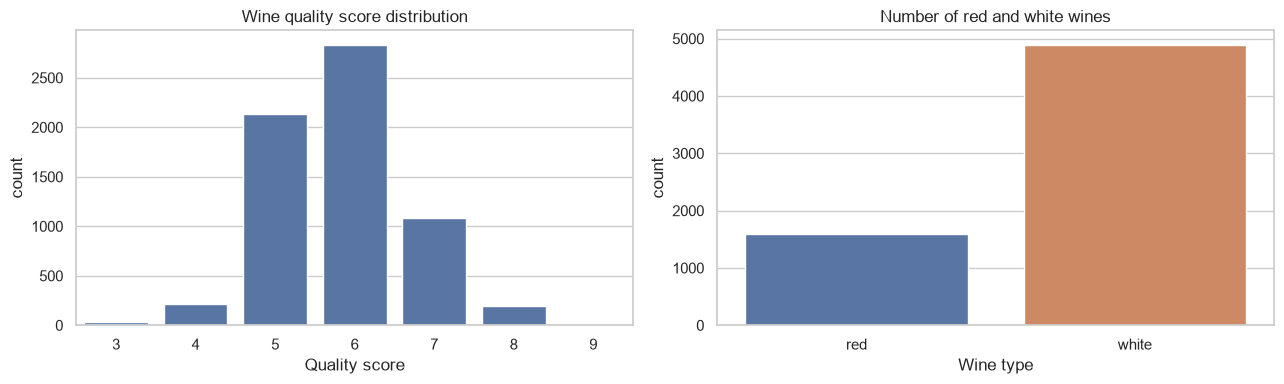

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df, x='quality', ax=axes[0])
axes[0].set_title('Wine quality score distribution')
axes[0].set_xlabel('Quality score')

sns.countplot(data=df, x='wine_type', hue='wine_type', legend=False, ax=axes[1])
axes[1].set_title('Number of red and white wines')
axes[1].set_xlabel('Wine type')
plt.tight_layout()
plt.show()

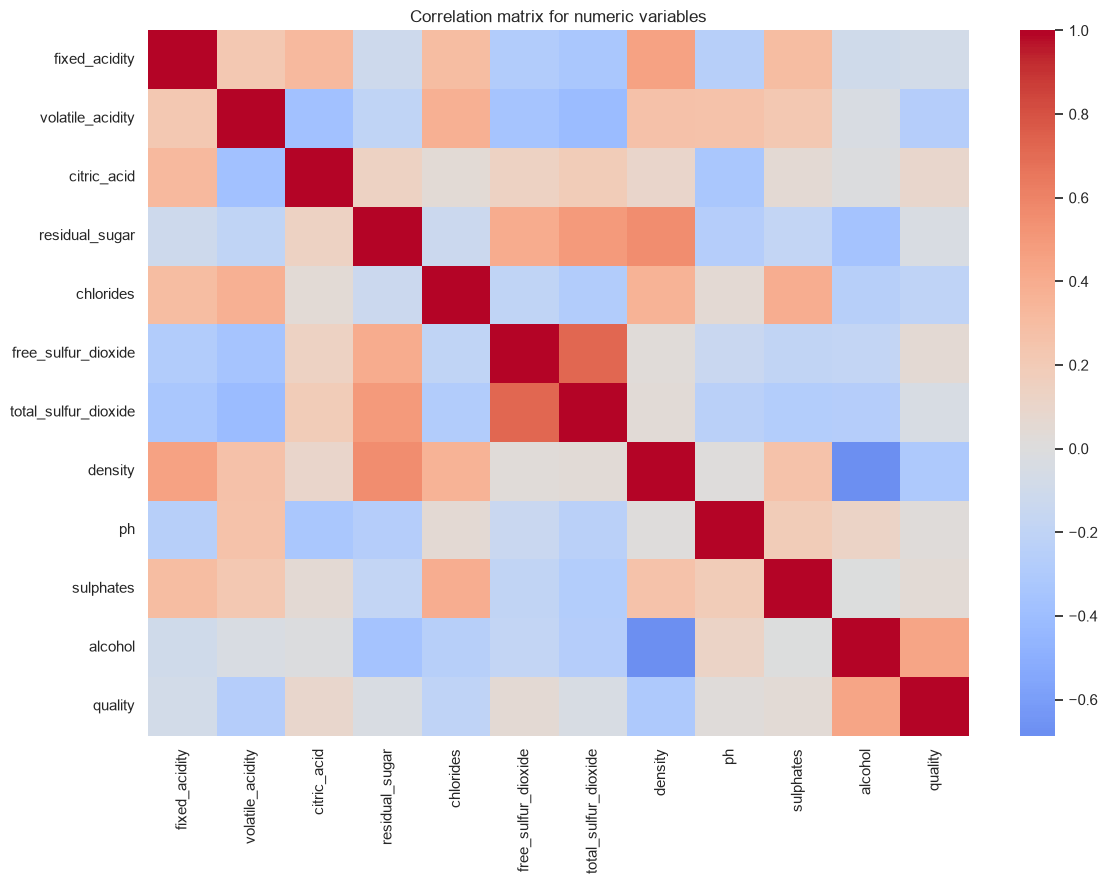

In [10]:
numeric_for_corr = df.select_dtypes(include=np.number)
plt.figure(figsize=(12, 9))
sns.heatmap(numeric_for_corr.corr(), cmap='coolwarm', center=0, annot=False)
plt.title('Correlation matrix for numeric variables')
plt.tight_layout()
plt.show()

### Initial observations to investigate

- Check the distribution of the target before choosing metrics.
- Check feature correlations, skewed variables and possible outliers.
- Wine quality is an ordinal score, but here we treat it as a numeric regression target and make a separate binary classification target.
- We **do not** use `quality` as an input feature. That would leak the answer to the model.

## 4. Define the features and two targets

For classification, a score of 6 or above is the positive class. This threshold is a project choice, not an official quality certification boundary.

In [11]:
TARGET = 'quality'
FEATURES = [col for col in df.columns if col != TARGET]

X = df[FEATURES].copy()
y_reg = df[TARGET].astype(float).copy()
y_clf = (df[TARGET] >= 6).astype(int)

print('Feature columns:', FEATURES)
print('Target is excluded from X:', TARGET not in X.columns)
print('Classification target counts:')
display(y_clf.value_counts().rename(index={0: 'quality < 6', 1: 'quality >= 6'}).to_frame('rows'))

Feature columns: ['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'ph', 'sulphates', 'alcohol', 'wine_type']
Target is excluded from X: True
Classification target counts:


,rows
quality,
quality >= 6,4113
quality < 6,2384


## 5. Build a reusable preprocessing pipeline

The current dataset mostly contains numeric features plus `wine_type`. We will:

- Impute numeric missing values with the median.
- Scale numeric features for models sensitive to feature scale.
- Impute categorical missing values with the most frequent category.
- One-hot encode categorical features.
- Keep preprocessing **inside** the model pipeline so it is learned separately within each training fold.

This is a key leakage-prevention pattern for interviews.

In [12]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_preprocessor = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_preprocessor = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('numeric', numeric_preprocessor, numeric_features),
    ('categorical', categorical_preprocessor, categorical_features)
], remainder='drop')

print('Numeric features:', len(numeric_features))
print('Categorical features:', categorical_features)

Numeric features: 11
Categorical features: ['wine_type']


## 6. Create train and test sets

Classification uses a stratified split to preserve the class proportions. Regression uses a regular randomized split. We will perform cross-validation only on the training set, then evaluate the chosen model on the held-out test set.

In [13]:
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_clf, test_size=0.20, random_state=RANDOM_STATE, stratify=y_clf
)
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X, y_reg, test_size=0.20, random_state=RANDOM_STATE
)

print('Classification train/test:', X_train_c.shape, X_test_c.shape)
print('Regression train/test:', X_train_r.shape, X_test_r.shape)

Classification train/test: (5197, 12) (1300, 12)
Regression train/test: (5197, 12) (1300, 12)


## 7. Classification model benchmarking

We'll compare a baseline and representative algorithms: Logistic Regression, K-Nearest Neighbors, Naive Bayes, Support Vector Machine, Decision Tree, Random Forest, and Gradient Boosting.

**Primary selection metric:** mean cross-validated F1 score. F1 balances precision and recall; it is more informative than accuracy alone when class proportions differ.

In [14]:
classification_models = {
    'Dummy baseline': DummyClassifier(strategy='prior'),
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    'KNN': KNeighborsClassifier(n_neighbors=7),
    'Gaussian Naive Bayes': GaussianNB(),
    'SVM (RBF)': SVC(C=1.0, kernel='rbf'),
    'Decision Tree': DecisionTreeClassifier(min_samples_leaf=3, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=150, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingClassifier(random_state=RANDOM_STATE)
}

cv_clf = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
classification_results = []
classification_pipelines = {}

for name, estimator in classification_models.items():
    pipe = Pipeline(steps=[('preprocess', preprocessor), ('model', estimator)])
    scores = cross_validate(
        pipe, X_train_c, y_train_c,
        cv=cv_clf,
        scoring={'f1': 'f1', 'accuracy': 'accuracy', 'roc_auc': 'roc_auc'},
        n_jobs=-1,
        return_train_score=False
    )
    classification_pipelines[name] = pipe
    classification_results.append({
        'model': name,
        'cv_f1_mean': scores['test_f1'].mean(),
        'cv_f1_std': scores['test_f1'].std(),
        'cv_accuracy_mean': scores['test_accuracy'].mean(),
        'cv_roc_auc_mean': scores['test_roc_auc'].mean()
    })

classification_results = pd.DataFrame(classification_results).sort_values('cv_f1_mean', ascending=False).reset_index(drop=True)
display(classification_results.style.format({
    'cv_f1_mean': '{:.3f}', 'cv_f1_std': '{:.3f}',
    'cv_accuracy_mean': '{:.3f}', 'cv_roc_auc_mean': '{:.3f}'
}))

,model,cv_f1_mean,cv_f1_std,cv_accuracy_mean,cv_roc_auc_mean
0,Random Forest,0.852,0.003,0.805,0.878
1,Gradient Boosting,0.824,0.008,0.770,0.835
2,SVM (RBF),0.822,0.008,0.766,0.830
3,KNN,0.809,0.005,0.749,0.806
4,Logistic Regression,0.804,0.001,0.740,0.801
5,Decision Tree,0.796,0.009,0.741,0.767
6,Dummy baseline,0.775,0.000,0.633,0.500
7,Gaussian Naive Bayes,0.747,0.002,0.662,0.728


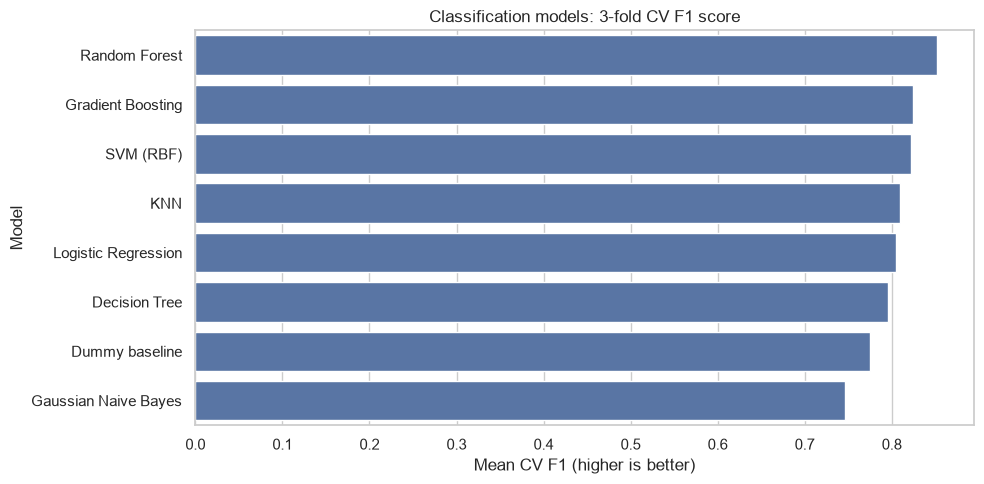

In [15]:
plt.figure(figsize=(10, 5))
sns.barplot(data=classification_results, x='cv_f1_mean', y='model')
plt.title('Classification models: 3-fold CV F1 score')
plt.xlabel('Mean CV F1 (higher is better)')
plt.ylabel('Model')
plt.tight_layout()
plt.show()

### Evaluate the selected classifier on the untouched test set

Selected model: Random Forest
Test accuracy:  0.833
Test precision: 0.846
Test recall:    0.900
Test F1:        0.872
Test ROC-AUC:   0.898

Classification report:
              precision    recall  f1-score   support

 quality < 6       0.81      0.72      0.76       477
quality >= 6       0.85      0.90      0.87       823

    accuracy                           0.83      1300
   macro avg       0.83      0.81      0.82      1300
weighted avg       0.83      0.83      0.83      1300



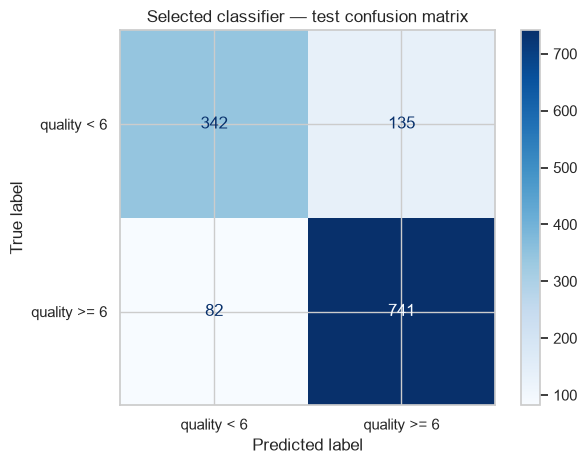

In [16]:
best_classifier_name = classification_results.iloc[0]['model']
best_classifier = classification_pipelines[best_classifier_name]
best_classifier.fit(X_train_c, y_train_c)
clf_predictions = best_classifier.predict(X_test_c)

print('Selected model:', best_classifier_name)
print(f'Test accuracy:  {accuracy_score(y_test_c, clf_predictions):.3f}')
print(f'Test precision: {precision_score(y_test_c, clf_predictions, zero_division=0):.3f}')
print(f'Test recall:    {recall_score(y_test_c, clf_predictions, zero_division=0):.3f}')
print(f'Test F1:        {f1_score(y_test_c, clf_predictions, zero_division=0):.3f}')

if hasattr(best_classifier, 'predict_proba'):
    clf_probabilities = best_classifier.predict_proba(X_test_c)[:, 1]
    print(f'Test ROC-AUC:   {roc_auc_score(y_test_c, clf_probabilities):.3f}')

print('\nClassification report:')
print(classification_report(y_test_c, clf_predictions, target_names=['quality < 6', 'quality >= 6'], zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test_c, clf_predictions, display_labels=['quality < 6', 'quality >= 6'], cmap='Blues')
plt.title('Selected classifier — test confusion matrix')
plt.tight_layout()
plt.show()

## 8. Regression model benchmarking

The regression target is the original numeric quality score. We'll compare a baseline, Linear Regression, Ridge, KNN, SVR, Decision Tree, Random Forest and Gradient Boosting.

**Primary selection metric:** mean cross-validated RMSE. Lower RMSE is better. We'll also report MAE and R² on the held-out test set.

In [17]:
regression_models = {
    'Dummy baseline': DummyRegressor(strategy='mean'),
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'KNN Regressor': KNeighborsRegressor(n_neighbors=7),
    'SVR (RBF)': SVR(C=10.0, epsilon=0.1),
    'Decision Tree': DecisionTreeRegressor(min_samples_leaf=3, random_state=RANDOM_STATE),
    'Random Forest': RandomForestRegressor(n_estimators=150, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingRegressor(random_state=RANDOM_STATE)
}

cv_reg = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
regression_results = []
regression_pipelines = {}

for name, estimator in regression_models.items():
    pipe = Pipeline(steps=[('preprocess', preprocessor), ('model', estimator)])
    scores = cross_validate(
        pipe, X_train_r, y_train_r,
        cv=cv_reg,
        scoring={'rmse': 'neg_root_mean_squared_error', 'mae': 'neg_mean_absolute_error', 'r2': 'r2'},
        n_jobs=-1,
        return_train_score=False
    )
    regression_pipelines[name] = pipe
    regression_results.append({
        'model': name,
        'cv_rmse_mean': -scores['test_rmse'].mean(),
        'cv_rmse_std': scores['test_rmse'].std(),
        'cv_mae_mean': -scores['test_mae'].mean(),
        'cv_r2_mean': scores['test_r2'].mean()
    })

regression_results = pd.DataFrame(regression_results).sort_values('cv_rmse_mean', ascending=True).reset_index(drop=True)
display(regression_results.style.format({
    'cv_rmse_mean': '{:.3f}', 'cv_rmse_std': '{:.3f}',
    'cv_mae_mean': '{:.3f}', 'cv_r2_mean': '{:.3f}'
}))

,model,cv_rmse_mean,cv_rmse_std,cv_mae_mean,cv_r2_mean
0,Random Forest,0.642,0.018,0.474,0.464
1,Gradient Boosting,0.687,0.011,0.533,0.385
2,SVR (RBF),0.699,0.017,0.523,0.363
3,KNN Regressor,0.711,0.013,0.542,0.342
4,Ridge Regression,0.734,0.012,0.570,0.298
5,Linear Regression,0.734,0.011,0.570,0.298
6,Decision Tree,0.817,0.021,0.559,0.131
7,Dummy baseline,0.876,0.017,0.691,-0.000


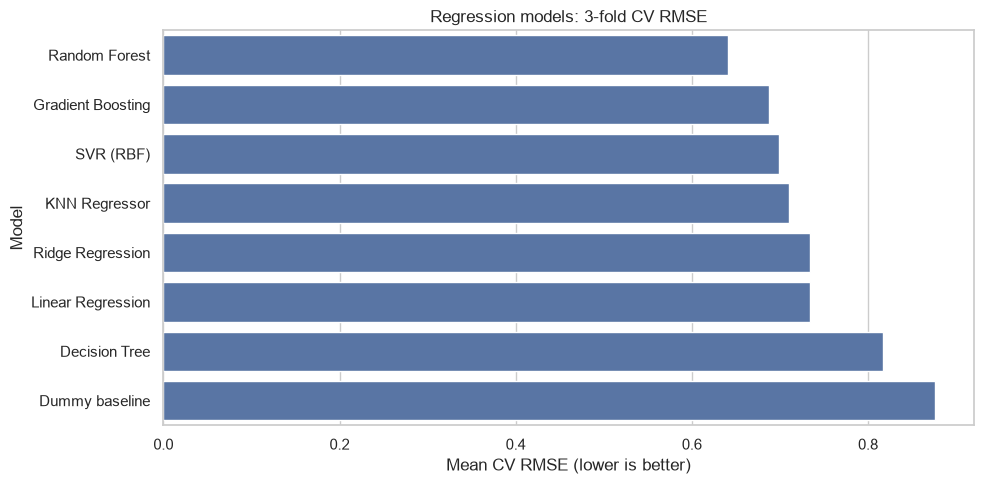

In [18]:
plt.figure(figsize=(10, 5))
sns.barplot(data=regression_results, x='cv_rmse_mean', y='model')
plt.title('Regression models: 3-fold CV RMSE')
plt.xlabel('Mean CV RMSE (lower is better)')
plt.ylabel('Model')
plt.tight_layout()
plt.show()

### Evaluate the selected regressor on the untouched test set

Selected model: Random Forest
Test RMSE: 0.615
Test MAE:  0.448
Test R²:   0.488


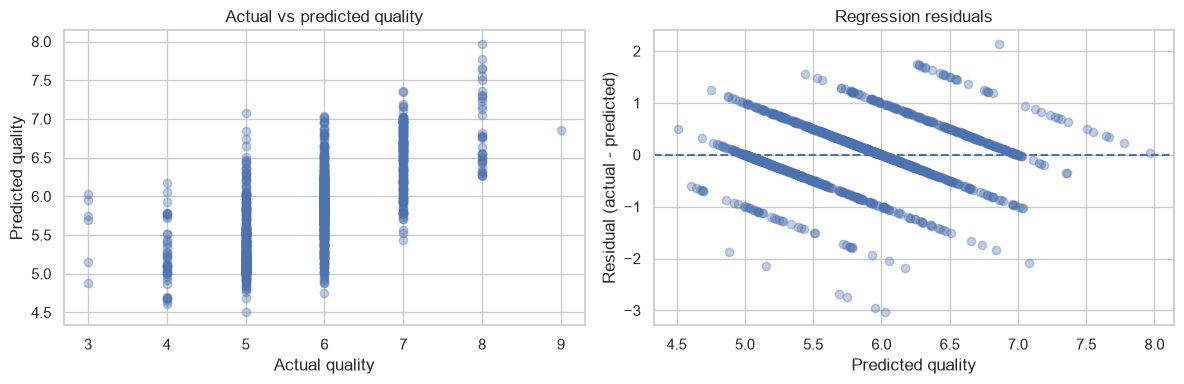

In [19]:
best_regressor_name = regression_results.iloc[0]['model']
best_regressor = regression_pipelines[best_regressor_name]
best_regressor.fit(X_train_r, y_train_r)
reg_predictions = best_regressor.predict(X_test_r)

rmse = np.sqrt(mean_squared_error(y_test_r, reg_predictions))
mae = mean_absolute_error(y_test_r, reg_predictions)
r2 = r2_score(y_test_r, reg_predictions)

print('Selected model:', best_regressor_name)
print(f'Test RMSE: {rmse:.3f}')
print(f'Test MAE:  {mae:.3f}')
print(f'Test R²:   {r2:.3f}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_test_r, reg_predictions, alpha=0.35)
axes[0].set_xlabel('Actual quality')
axes[0].set_ylabel('Predicted quality')
axes[0].set_title('Actual vs predicted quality')

residuals = y_test_r - reg_predictions
axes[1].scatter(reg_predictions, residuals, alpha=0.35)
axes[1].axhline(0, linestyle='--')
axes[1].set_xlabel('Predicted quality')
axes[1].set_ylabel('Residual (actual - predicted)')
axes[1].set_title('Regression residuals')
plt.tight_layout()
plt.show()

## 9. Save the fitted pipelines and reports

We save **the entire pipeline**, not just the estimator. When you reload it, the same imputation, scaling, encoding, and model steps are applied to new records.

In [20]:
classification_model_path = MODEL_DIR / 'wine_quality_classifier.joblib'
regression_model_path = MODEL_DIR / 'wine_quality_regressor.joblib'

joblib.dump(best_classifier, classification_model_path)
joblib.dump(best_regressor, regression_model_path)
classification_results.to_csv(REPORT_DIR / 'classification_cv_results.csv', index=False)
regression_results.to_csv(REPORT_DIR / 'regression_cv_results.csv', index=False)

print('Saved classifier:', classification_model_path.resolve())
print('Saved regressor:', regression_model_path.resolve())
print('Saved model comparison CSVs in:', REPORT_DIR.resolve())

Saved classifier: /Users/k.r.saravanadeep/PycharmProjects/wine-quality-ml-notebook/models/wine_quality_classifier.joblib
Saved regressor: /Users/k.r.saravanadeep/PycharmProjects/wine-quality-ml-notebook/models/wine_quality_regressor.joblib
Saved model comparison CSVs in: /Users/k.r.saravanadeep/PycharmProjects/wine-quality-ml-notebook/reports


## 10. Test inference on new records

In [21]:
# Use rows from the feature table as sample inputs. These are examples for testing the pipeline,
# not new independent measurements. In a real app, collect the same 12 feature columns from a user.
sample_wines = X_test_c.iloc[:3].copy()

predicted_quality_group = best_classifier.predict(sample_wines)
predicted_quality_score = best_regressor.predict(sample_wines)

sample_output = sample_wines[['wine_type']].copy()
sample_output['predicted_quality_group'] = np.where(predicted_quality_group == 1, 'quality >= 6', 'quality < 6')
sample_output['predicted_numeric_quality'] = np.round(predicted_quality_score, 2)
display(sample_output)

# Verify that saved pipelines can be loaded and still make predictions.
loaded_classifier = joblib.load(classification_model_path)
loaded_regressor = joblib.load(regression_model_path)
print('Reloaded classifier predictions:', loaded_classifier.predict(sample_wines).tolist())
print('Reloaded regressor predictions:', np.round(loaded_regressor.predict(sample_wines), 2).tolist())

,wine_type,predicted_quality_group,predicted_numeric_quality
714,red,quality < 6,5.12
2068,white,quality < 6,5.35
2660,white,quality >= 6,5.34


Reloaded classifier predictions: [0, 0, 1]
Reloaded regressor predictions: [5.12, 5.35, 5.34]


# 11. Hyperparameter Tuning

Optimize the selected classification and regression models
using RandomizedSearchCV.

In [22]:
from sklearn.model_selection import RandomizedSearchCV

In [23]:
# Hyperparameter search space for the selected classifier

classifier = best_classifier.named_steps['model']

if isinstance(classifier, RandomForestClassifier):
    param_grid = {
        'model__n_estimators': [100, 200, 300, 400],
        'model__max_depth': [None, 10, 20, 30],
        'model__min_samples_split': [2, 5, 10],
        'model__min_samples_leaf': [1, 2, 4],
        'model__max_features': ['sqrt', 'log2']
    }

elif isinstance(classifier, GradientBoostingClassifier):
    param_grid = {
        'model__n_estimators': [100, 150, 200, 300],
        'model__learning_rate': [0.01, 0.05, 0.1, 0.2],
        'model__max_depth': [2, 3, 4],
        'model__subsample': [0.8, 1.0]
    }

elif isinstance(classifier, DecisionTreeClassifier):
    param_grid = {
        'model__max_depth': [None, 5, 10, 20, 30],
        'model__min_samples_split': [2, 5, 10],
        'model__min_samples_leaf': [1, 2, 4],
        'model__criterion': ['gini', 'entropy']
    }

elif isinstance(classifier, LogisticRegression):
    param_grid = {
        'model__C': [0.01, 0.1, 1, 10, 100],
        'model__solver': ['lbfgs', 'liblinear']
    }

elif isinstance(classifier, KNeighborsClassifier):
    param_grid = {
        'model__n_neighbors': [3, 5, 7, 9, 11, 15],
        'model__weights': ['uniform', 'distance'],
        'model__p': [1, 2]
    }

elif isinstance(classifier, SVC):
    param_grid = {
        'model__C': [0.1, 1, 10, 100],
        'model__gamma': ['scale', 'auto', 0.01, 0.1, 1],
        'model__kernel': ['rbf', 'linear']
    }

elif isinstance(classifier, GaussianNB):
    param_grid = {
        'model__var_smoothing': [1e-11, 1e-10, 1e-9, 1e-8, 1e-7]
    }

else:
    raise ValueError(f"Hyperparameter tuning not configured for: {type(classifier).__name__}")

print("Selected classifier:", best_classifier_name)
print("Number of hyperparameters:", len(param_grid))
print("Search space:", param_grid)

Selected classifier: Random Forest
Number of hyperparameters: 5
Search space: {'model__n_estimators': [100, 200, 300, 400], 'model__max_depth': [None, 10, 20, 30], 'model__min_samples_split': [2, 5, 10], 'model__min_samples_leaf': [1, 2, 4], 'model__max_features': ['sqrt', 'log2']}


In [26]:
classifier_search = RandomizedSearchCV(
    estimator=best_classifier,
    param_distributions=clf_param_grid,
    n_iter=20,
    scoring='f1',
    cv=cv_clf,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

classifier_search.fit(X_train_c, y_train_c)

tuned_classifier = classifier_search.best_estimator_

print("Best parameters:")
print(classifier_search.best_params_)

print("\nBest cross-validation F1:")
print(classifier_search.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best parameters:
{'model__n_estimators': 100, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_features': 'log2', 'model__max_depth': 20}

Best cross-validation F1:
0.8555525519097764


In [27]:
clf_tuning_results = pd.DataFrame(classifier_search.cv_results_)

clf_tuning_results = clf_tuning_results[
    ['rank_test_score', 'mean_test_score', 'std_test_score',
     'mean_train_score', 'params']
].sort_values('rank_test_score')

display(clf_tuning_results.head(10))

,rank_test_score,mean_test_score,std_test_score,mean_train_score,params
2,1,0.855553,0.000603,0.995611,"{'model__n_estimators': 100, 'model__min_sampl..."
5,1,0.855553,0.000603,0.995611,"{'model__n_estimators': 100, 'model__min_sampl..."
9,3,0.854584,0.003318,0.996365,"{'model__n_estimators': 200, 'model__min_sampl..."
12,4,0.853267,0.006040,1.000000,"{'model__n_estimators': 200, 'model__min_sampl..."
11,5,0.853205,0.002815,0.995458,"{'model__n_estimators': 100, 'model__min_sampl..."
16,6,0.853021,0.003359,0.991472,"{'model__n_estimators': 200, 'model__min_sampl..."
15,7,0.852764,0.005181,0.988313,"{'model__n_estimators': 300, 'model__min_sampl..."
13,8,0.850591,0.001632,0.991162,"{'model__n_estimators': 100, 'model__min_sampl..."
0,9,0.850469,0.003569,0.988611,"{'model__n_estimators': 100, 'model__min_sampl..."
8,10,0.846134,0.006626,0.963346,"{'model__n_estimators': 200, 'model__min_sampl..."


TUNED CLASSIFICATION RESULTS
----------------------------------------
Accuracy:  0.842
Precision: 0.853
Recall:    0.905
F1 Score:  0.879
ROC-AUC:   0.902

Classification Report:
              precision    recall  f1-score   support

 quality < 6       0.82      0.73      0.77       477
quality >= 6       0.85      0.91      0.88       823

    accuracy                           0.84      1300
   macro avg       0.84      0.82      0.83      1300
weighted avg       0.84      0.84      0.84      1300



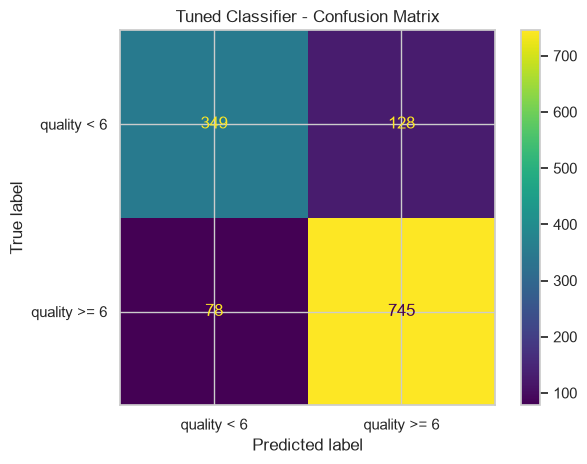

In [28]:
tuned_clf_predictions = tuned_classifier.predict(X_test_c)

tuned_clf_accuracy = accuracy_score(y_test_c, tuned_clf_predictions)
tuned_clf_precision = precision_score(
    y_test_c, tuned_clf_predictions, zero_division=0
)
tuned_clf_recall = recall_score(
    y_test_c, tuned_clf_predictions, zero_division=0
)
tuned_clf_f1 = f1_score(
    y_test_c, tuned_clf_predictions, zero_division=0
)

print("TUNED CLASSIFICATION RESULTS")
print("-" * 40)
print(f"Accuracy:  {tuned_clf_accuracy:.3f}")
print(f"Precision: {tuned_clf_precision:.3f}")
print(f"Recall:    {tuned_clf_recall:.3f}")
print(f"F1 Score:  {tuned_clf_f1:.3f}")

if hasattr(tuned_classifier, 'predict_proba'):
    tuned_clf_probabilities = tuned_classifier.predict_proba(X_test_c)[:, 1]
    print(
        f"ROC-AUC:   "
        f"{roc_auc_score(y_test_c, tuned_clf_probabilities):.3f}"
    )

print("\nClassification Report:")
print(classification_report(
    y_test_c,
    tuned_clf_predictions,
    target_names=['quality < 6', 'quality >= 6'],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test_c,
    tuned_clf_predictions,
    display_labels=['quality < 6', 'quality >= 6']
)
plt.title("Tuned Classifier - Confusion Matrix")
plt.tight_layout()
plt.show()

In [29]:
classification_comparison = pd.DataFrame({
    'Model': ['Baseline', 'Tuned'],
    'Accuracy': [
        accuracy_score(y_test_c, clf_predictions),
        tuned_clf_accuracy
    ],
    'F1 Score': [
        f1_score(y_test_c, clf_predictions, zero_division=0),
        tuned_clf_f1
    ],
    'Precision': [
        precision_score(y_test_c, clf_predictions, zero_division=0),
        tuned_clf_precision
    ],
    'Recall': [
        recall_score(y_test_c, clf_predictions, zero_division=0),
        tuned_clf_recall
    ]
})

display(classification_comparison.round(3))

,Model,Accuracy,F1 Score,Precision,Recall
0,Baseline,0.833,0.872,0.846,0.900
1,Tuned,0.842,0.879,0.853,0.905


In [36]:
# Hyperparameter search space for the selected Regression 
regressor = best_regressor.named_steps['model']

regression_param_grids = {
    'RandomForestRegressor': {
        'model__n_estimators': [100, 200, 300, 400],
        'model__max_depth': [None, 10, 20, 30],
        'model__min_samples_split': [2, 5, 10],
        'model__min_samples_leaf': [1, 2, 4],
        'model__max_features': [1.0, 'sqrt', 'log2']
    },

    'GradientBoostingRegressor': {
        'model__n_estimators': [100, 150, 200, 300],
        'model__learning_rate': [0.01, 0.05, 0.1, 0.2],
        'model__max_depth': [2, 3, 4],
        'model__subsample': [0.8, 1.0],
        'model__loss': ['squared_error', 'huber']
    },

    'DecisionTreeRegressor': {
        'model__max_depth': [None, 5, 10, 20, 30],
        'model__min_samples_split': [2, 5, 10],
        'model__min_samples_leaf': [1, 2, 4],
        'model__criterion': ['squared_error', 'friedman_mse']
    },

    'KNeighborsRegressor': {
        'model__n_neighbors': [3, 5, 7, 9, 11, 15],
        'model__weights': ['uniform', 'distance'],
        'model__p': [1, 2]
    },

    'SVR': {
        'model__C': [0.1, 1, 10, 50, 100],
        'model__epsilon': [0.01, 0.1, 0.2, 0.5],
        'model__kernel': ['rbf', 'linear'],
        'model__gamma': ['scale', 'auto']
    },

    'Ridge': {
        'model__alpha': [0.01, 0.1, 1, 10, 100, 1000],
        'model__solver': ['auto', 'svd', 'cholesky']
    }
}

model_type = type(regressor).__name__

if model_type not in regression_param_grids:
    raise ValueError(
        f"No tuning grid defined for {model_type}. "
        "This model may not have useful hyperparameters to tune."
    )

reg_param_grid = regression_param_grids[model_type]

print("Selected regressor:", best_regressor_name)
print("Model type:", model_type)
print("Search parameters:", reg_param_grid)

Selected regressor: Random Forest
Model type: RandomForestRegressor
Search parameters: {'model__n_estimators': [100, 200, 300, 400], 'model__max_depth': [None, 10, 20, 30], 'model__min_samples_split': [2, 5, 10], 'model__min_samples_leaf': [1, 2, 4], 'model__max_features': [1.0, 'sqrt', 'log2']}


In [31]:
regressor_search = RandomizedSearchCV(
    estimator=best_regressor,
    param_distributions=reg_param_grid,
    n_iter=20,
    scoring='neg_root_mean_squared_error',
    cv=cv_reg,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

regressor_search.fit(X_train_r, y_train_r)

tuned_regressor = regressor_search.best_estimator_

print("Best parameters:")
print(regressor_search.best_params_)

print("\nBest cross-validation RMSE:")
print(-regressor_search.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best parameters:
{'model__n_estimators': 400, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 'log2', 'model__max_depth': None}

Best cross-validation RMSE:
0.6280884239995991


In [32]:
reg_tuning_results = pd.DataFrame(regressor_search.cv_results_)

reg_tuning_results = reg_tuning_results[
    ['rank_test_score', 'mean_test_score', 'std_test_score',
     'mean_train_score', 'params']
].sort_values('rank_test_score')

# Convert negative RMSE scores into positive RMSE values
reg_tuning_results['mean_test_RMSE'] = (
    -reg_tuning_results['mean_test_score']
)

display(reg_tuning_results.head(10))

,rank_test_score,mean_test_score,std_test_score,mean_train_score,params,mean_test_RMSE
1,1,-0.628088,0.017584,-0.231207,"{'model__n_estimators': 400, 'model__min_sampl...",0.628088
14,1,-0.628088,0.017584,-0.231207,"{'model__n_estimators': 400, 'model__min_sampl...",0.628088
17,3,-0.630285,0.019450,-0.235017,"{'model__n_estimators': 100, 'model__min_sampl...",0.630285
6,4,-0.638108,0.018202,-0.351483,"{'model__n_estimators': 300, 'model__min_sampl...",0.638108
13,5,-0.645947,0.016554,-0.349265,"{'model__n_estimators': 300, 'model__min_sampl...",0.645947
18,6,-0.646394,0.015734,-0.349792,"{'model__n_estimators': 200, 'model__min_sampl...",0.646394
16,7,-0.646889,0.017338,-0.422637,"{'model__n_estimators': 300, 'model__min_sampl...",0.646889
5,8,-0.647002,0.017258,-0.423262,"{'model__n_estimators': 400, 'model__min_sampl...",0.647002
3,9,-0.648081,0.017449,-0.400299,"{'model__n_estimators': 300, 'model__min_sampl...",0.648081
0,10,-0.650460,0.017147,-0.453567,"{'model__n_estimators': 100, 'model__min_sampl...",0.650460


TUNED REGRESSION RESULTS
----------------------------------------
RMSE: 0.595
MAE:  0.428
R²:   0.521


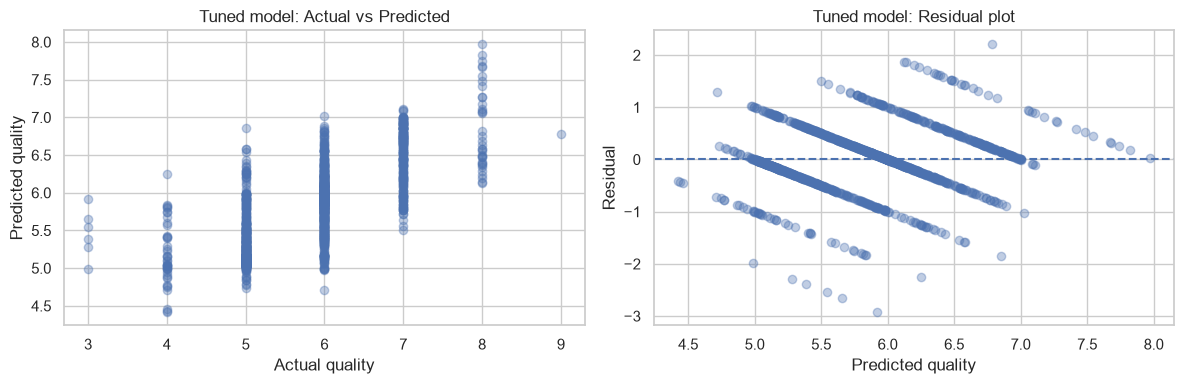

In [33]:
tuned_reg_predictions = tuned_regressor.predict(X_test_r)

tuned_rmse = np.sqrt(
    mean_squared_error(y_test_r, tuned_reg_predictions)
)
tuned_mae = mean_absolute_error(y_test_r, tuned_reg_predictions)
tuned_r2 = r2_score(y_test_r, tuned_reg_predictions)

print("TUNED REGRESSION RESULTS")
print("-" * 40)
print(f"RMSE: {tuned_rmse:.3f}")
print(f"MAE:  {tuned_mae:.3f}")
print(f"R²:   {tuned_r2:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(y_test_r, tuned_reg_predictions, alpha=0.35)
axes[0].set_xlabel("Actual quality")
axes[0].set_ylabel("Predicted quality")
axes[0].set_title("Tuned model: Actual vs Predicted")

residuals = y_test_r - tuned_reg_predictions

axes[1].scatter(tuned_reg_predictions, residuals, alpha=0.35)
axes[1].axhline(0, linestyle='--')
axes[1].set_xlabel("Predicted quality")
axes[1].set_ylabel("Residual")
axes[1].set_title("Tuned model: Residual plot")

plt.tight_layout()
plt.show()

In [34]:
regression_comparison = pd.DataFrame({
    'Model': ['Baseline', 'Tuned'],
    'RMSE': [
        rmse,
        tuned_rmse
    ],
    'MAE': [
        mae,
        tuned_mae
    ],
    'R2 Score': [
        r2,
        tuned_r2
    ]
})

display(regression_comparison.round(3))

,Model,RMSE,MAE,R2 Score
0,Baseline,0.615,0.448,0.488
1,Tuned,0.595,0.428,0.521


In [35]:
#save the model

tuned_classifier_path = MODEL_DIR / 'wine_quality_classifier_tuned.joblib'
tuned_regressor_path = MODEL_DIR / 'wine_quality_regressor_tuned.joblib'

joblib.dump(tuned_classifier, tuned_classifier_path)
joblib.dump(tuned_regressor, tuned_regressor_path)

clf_tuning_results.to_csv(
    REPORT_DIR / 'classification_tuning_results.csv',
    index=False
)

reg_tuning_results.to_csv(
    REPORT_DIR / 'regression_tuning_results.csv',
    index=False
)

classification_comparison.to_csv(
    REPORT_DIR / 'classification_baseline_vs_tuned.csv',
    index=False
)

regression_comparison.to_csv(
    REPORT_DIR / 'regression_baseline_vs_tuned.csv',
    index=False
)

print("Tuned classifier saved:", tuned_classifier_path)
print("Tuned regressor saved:", tuned_regressor_path)
print("Tuning reports saved in:", REPORT_DIR)

Tuned classifier saved: /Users/k.r.saravanadeep/PycharmProjects/wine-quality-ml-notebook/models/wine_quality_classifier_tuned.joblib
Tuned regressor saved: /Users/k.r.saravanadeep/PycharmProjects/wine-quality-ml-notebook/models/wine_quality_regressor_tuned.joblib
Tuning reports saved in: /Users/k.r.saravanadeep/PycharmProjects/wine-quality-ml-notebook/reports
